# Entregas no e-commerce brasileiro
**Análise exploratória e priorização de pedidos da Olist**

A equipe de logística precisa decidir quais pedidos acompanhar de perto já na compra. Medimos atrasos entre pedidos entregues e simulamos uma fila de revisão com dados disponíveis no checkout. O recorte cobre compras de janeiro de 2017 a agosto de 2018. Um pedido está atrasado quando chega depois da data prometida, em dias corridos.

Fonte: [Brazilian E-Commerce Public Dataset by Olist, versão 2](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). A metodologia de coleta e as conclusões estão na documentação do repositório.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
from sklearn.metrics import PrecisionRecallDisplay

pasta = Path.cwd().resolve()
raiz = next(p for p in (pasta, *pasta.parents) if (p / "src" / "analise.py").is_file())
sys.path.insert(0, str(raiz))

from src.analise import (
    CATEGORICAS, NUMERICAS, avaliar_modelo, exportar_painel, preparar_pedidos, resumo_por,
)

AZUL = "#145C64"
ESCALA = "#D0E5E5"
LARANJA = "#BD5529"
TEXTO = "#1B3037"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#CDDADB", "text.color": TEXTO, "axes.labelcolor": TEXTO,
    "xtick.color": TEXTO, "ytick.color": TEXTO, "grid.color": "#E0E8E9",
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
    "axes.axisbelow": True, "figure.dpi": 125,
})
pd.options.display.float_format = "{:.3f}".format

## 1. Coleta, limpeza e unidade de análise

O script lê cinco CSVs no ZIP oficial. Os itens são agregados por pedido antes da junção, para evitar duplicar pedidos de vários itens. Para a EDA de satisfação, fica a resposta mais recente com nota válida. Entram apenas pedidos marcados como entregues, com data de entrega e promessa coerentes e com informações mínimas de itens e UF.

In [2]:
pedidos, auditoria, status = preparar_pedidos()
display(auditoria.to_frame())
display(status.to_frame())

atrasados = pedidos.loc[pedidos.atrasou]
resumo = pd.Series({
    "Entregues na coorte": len(pedidos),
    "Entregues após o prazo": len(atrasados),
    "Taxa de atraso (%)": pedidos.atrasou.mean() * 100,
    "Dias até a entrega (mediana)": pedidos.dias_ate_entrega.median(),
    "Dias em atraso, entre os atrasados (mediana)": atrasados.dias_atraso.median(),
})
display(resumo.to_frame("valor"))
display(pedidos[["dias_prometidos", "dias_ate_entrega", "frete", "valor"]].describe().T)

,pedidos
Pedidos no arquivo,99441
Pedidos dentro do recorte,99092
Pedidos com status entregue,96211
Entregues excluídos por datas ausentes ou incoerentes,8
Excluídos por falta de itens ou UF,0
Pedidos na coorte,96203
Pedidos com nota,95560


,pedidos
status,
delivered,96211
shipped,1097
unavailable,602
canceled,580
processing,299
invoiced,296
created,5
approved,2


,valor
Entregues na coorte,96203.000
Entregues após o prazo,6531.000
Taxa de atraso (%),6.789
Dias até a entrega (mediana),10.000
"Dias em atraso, entre os atrasados (mediana)",7.000


,count,mean,std,min,25%,50%,75%,max
dias_prometidos,96203.000,24.285,8.601,3.000,19.000,24.000,29.000,156.000
dias_ate_entrega,96203.000,12.477,9.539,0.000,7.000,10.000,16.000,210.000
frete,96203.000,22.785,21.566,0.000,13.850,17.170,24.010,1794.960
valor,96203.000,137.000,209.121,0.850,45.900,86.500,149.900,13440.000


## 2. Tendência mensal e concentração geográfica

O volume é o denominador da taxa de atraso. O gráfico por UF inclui os oito destinos com maior volume, ordenados pela taxa. Com isso, conseguimos ler os destinos mais relevantes para a operação sem promover UFs com poucas observações.

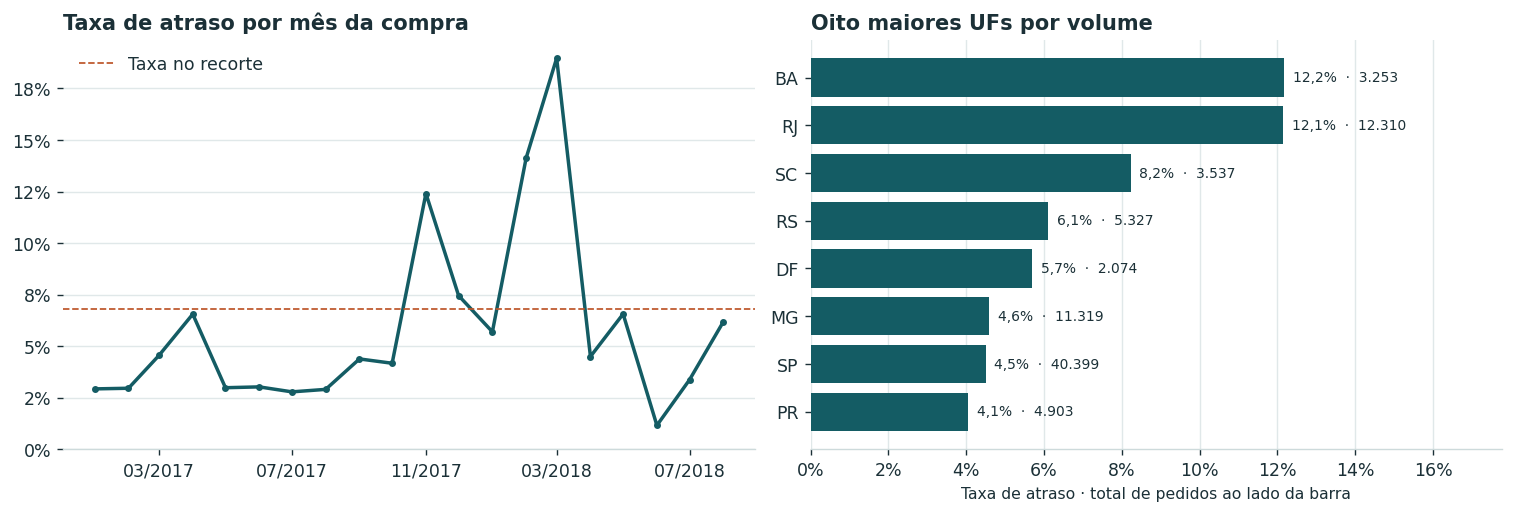

,pedidos,atrasados,dias_ate_entrega_mediana,taxa_atraso
mes_compra,,,,
2018-03-01,7003,1328,13.000,0.190
2018-02-01,6555,926,14.000,0.141
2017-11-01,7288,904,13.000,0.124
2017-12-01,5513,411,13.000,0.075
2018-05-01,6749,443,9.000,0.066


,pedidos,atrasados,dias_ate_entrega_mediana,taxa_atraso
uf_destino,,,,
SP,40399,1817,7.000,0.045
RJ,12310,1495,12.000,0.121
MG,11319,519,10.000,0.046
RS,5327,325,13.000,0.061
PR,4903,199,10.000,0.041
SC,3537,291,13.000,0.082
BA,3253,396,17.000,0.122
DF,2074,118,11.000,0.057


In [3]:
mensal = resumo_por(pedidos, "mes_compra")
ufs = resumo_por(pedidos, "uf_destino")
principais_ufs = ufs.nlargest(8, "pedidos").sort_values("taxa_atraso")

fig, (tempo, estado) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
tempo.plot(mensal.index, mensal.taxa_atraso, color=AZUL, marker="o", ms=3, lw=2)
tempo.axhline(pedidos.atrasou.mean(), color=LARANJA, ls="--", lw=1, label="Taxa no recorte")
tempo.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
tempo.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
tempo.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
tempo.set_title("Taxa de atraso por mês da compra")
tempo.set_ylim(bottom=0)
tempo.grid(axis="y")
tempo.legend(frameon=False)

barras = estado.barh(principais_ufs.index, principais_ufs.taxa_atraso, color=AZUL)
rotulos = [
    f"{taxa:.1%}".replace(".", ",") + "  ·  " + f"{total:,}".replace(",", ".")
    for taxa, total in zip(principais_ufs.taxa_atraso, principais_ufs.pedidos)
]
estado.bar_label(barras, labels=rotulos, padding=5, fontsize=8)
estado.set_xlim(0, principais_ufs.taxa_atraso.max() * 1.46)
estado.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
estado.set_title("Oito maiores UFs por volume")
estado.set_xlabel("Taxa de atraso · total de pedidos ao lado da barra", fontsize=9)
estado.grid(axis="x")
plt.show()
display(mensal.sort_values("taxa_atraso", ascending=False).head(5))
display(ufs.nlargest(8, "pedidos"))

## 3. Rotas, prazo prometido e satisfação

A rota usa a UF cadastrada de cada vendedor como aproximação da origem. Uma rota mista reúne itens de vendedores da UF do comprador e de outras UFs. As taxas por faixa de prazo descrevem a coorte e podem refletir diferenças de rota, destino e composição dos pedidos.

A nota é um resultado posterior à compra. A comparação de satisfação considera apenas os pedidos com avaliação e descreve uma associação.

,pedidos,atrasados,dias_ate_entrega_mediana,taxa_atraso
rota,,,,
Dentro da UF,34489,1562,6.000,0.045
Entre UFs,61468,4968,13.000,0.081
Mista,246,1,6.000,0.004


,pedidos,atrasados,dias_ate_entrega_mediana,taxa_atraso
faixa_prazo,,,,
Até 7 dias,1260,213,4.000,0.169
8 a 14 dias,10742,532,5.000,0.050
15 a 21 dias,23303,1729,8.000,0.074
22 a 30 dias,41290,3074,12.000,0.074
31+ dias,19608,983,15.000,0.050


,avaliacoes,nota_media,proporcao_notas_1_2
situacao,,,
Atrasado,6378,2.271,0.624
No prazo,89182,4.291,0.092


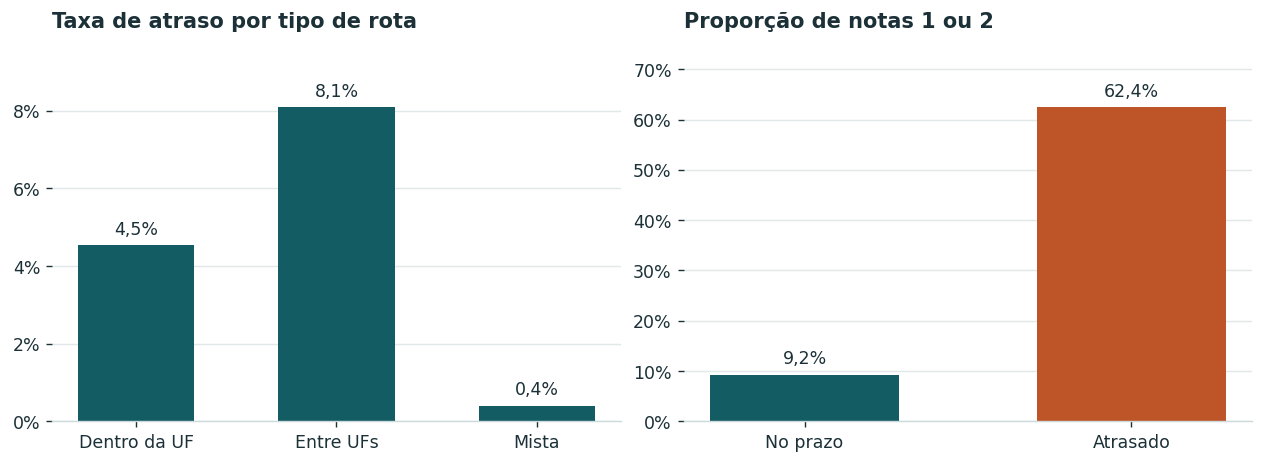

In [4]:
rotas = resumo_por(pedidos, "rota")
prazos = resumo_por(pedidos, "faixa_prazo")
avaliados = pedidos.dropna(subset=["nota"]).copy()
avaliados["situacao"] = avaliados.atrasou.map({False: "No prazo", True: "Atrasado"})
avaliados["nota_baixa"] = avaliados.nota.le(2)
satisfacao = avaliados.groupby("situacao").agg(
    avaliacoes=("nota", "size"), nota_media=("nota", "mean"),
    proporcao_notas_1_2=("nota_baixa", "mean"),
)
display(rotas, prazos, satisfacao)

fig, (rota, nota) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
ordem_rotas = ["Dentro da UF", "Entre UFs", "Mista"]
ordem_notas = ["No prazo", "Atrasado"]
for eixo, dados, titulo, cores in [
    (rota, rotas.taxa_atraso.reindex(ordem_rotas), "Taxa de atraso por tipo de rota", [AZUL] * 3),
    (nota, satisfacao.proporcao_notas_1_2.reindex(ordem_notas), "Proporção de notas 1 ou 2", [AZUL, LARANJA]),
]:
    barras = eixo.bar(dados.index, dados, color=cores, width=0.58)
    eixo.bar_label(barras, labels=[f"{v:.1%}".replace(".", ",") for v in dados], padding=4)
    eixo.set_ylim(0, dados.max() * 1.22)
    eixo.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    eixo.grid(axis="y")
    eixo.set_title(titulo)
plt.show()

### Relações entre variáveis

A correlação de Spearman resume associações monotônicas. O prazo prometido, o frete e o valor dos itens são medidos na compra. Os dias até a entrega e a nota foram incluídos para descrever o desfecho e ficam fora do modelo. O atraso é derivado das datas, por isso a correlação com o tempo real de entrega tem relação com a própria definição da variável.

In [5]:
campos = ["dias_prometidos", "frete", "valor", "n_itens", "dias_ate_entrega", "nota", "atrasou"]
correlacoes = pedidos[campos].corr(method="spearman")
display(correlacoes.round(2))

,dias_prometidos,frete,valor,n_itens,dias_ate_entrega,nota,atrasou
dias_prometidos,1.000,0.460,0.120,0.010,0.520,-0.060,-0.020
frete,0.460,1.000,0.470,0.380,0.380,-0.090,0.050
valor,0.120,0.470,1.000,0.180,0.100,-0.030,0.020
n_itens,0.010,0.380,0.180,1.000,-0.030,-0.110,-0.020
dias_ate_entrega,0.520,0.380,0.100,-0.030,1.000,-0.230,0.390
nota,-0.060,-0.090,-0.030,-0.110,-0.230,1.000,-0.310
atrasou,-0.020,0.050,0.020,-0.020,0.390,-0.310,1.000


## 4. Simulação de uma fila de revisão antecipada

Usamos regressão logística com variáveis de compra. As partições são cronológicas. No treino e na validação, exigimos que o desfecho já fosse conhecido antes do início da janela seguinte. A decisão operacional é simulada com um limiar ajustado na validação para sinalizar até 15% dos pedidos. O limiar é mantido no teste para medir como a carga de revisão muda em meses posteriores. Simulamos também uma cota diária de até 15%: o score é calculado na compra e a fila é ordenada no fim do dia.

A referência para a precisão média (AP, em inglês) é a taxa de atraso do período, correspondente a uma pontuação constante. Para a fila, reportamos precisão, revocação, percentual sinalizado e lift em relação à taxa de atraso.

Comparamos a regressão logística com uma regra simples que ordena os pedidos pela taxa de atraso histórica da UF de destino, calculada apenas no treino. UFs sem histórico recebem a taxa geral do treino. A comparação usa a mesma cota por dia e desempata pela ordem da compra e pelo identificador do pedido.

Limiar definido na validação: 0.0588
Atrasos adicionais capturados com a mesma cota: 63
Variáveis da compra usadas no modelo: log_itens, log_vendedores, log_valor, log_frete, uf_destino, rota, faixa_prazo, dia_semana, turno


,pedidos,atrasados
particao,,
Treino,40930,1762
Validação,16782,1158
Teste,32150,1421


,Validação · limiar,Teste · limiar,Teste · cota diária,Teste · regra por UF
pedidos,16782.000,32150.000,32150.000,32150.000
atrasos,1158.000,1421.000,1421.000,1421.000
taxa_atraso,0.069,0.044,0.044,0.044
ap_referencia_aleatoria,0.069,0.044,0.044,0.044
ap_score,0.131,0.080,0.080,0.064
roc_auc,0.651,0.652,0.652,0.583
alertas,2517.000,7689.000,4744.000,4744.000
atrasos_detectados,350.000,588.000,431.000,368.000
percentual_alertado,0.150,0.239,0.148,0.148
precisao,0.139,0.076,0.091,0.078


,alertas,atrasos_detectados,precisao,revocacao
Taxa histórica por UF,4744,368,0.078,0.259
Regressão logística,4744,431,0.091,0.303


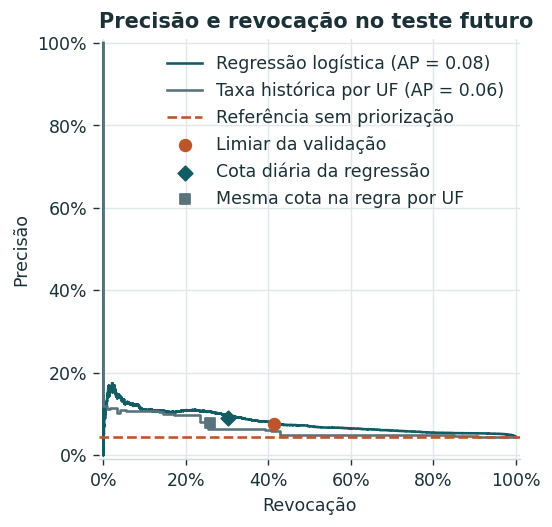

In [6]:
teste, metricas, particoes, limiar = avaliar_modelo(pedidos)
display(particoes)
print(f"Limiar definido na validação: {limiar:.4f}")
display(metricas.T)
comparacao = metricas.loc[
    ["Teste · regra por UF", "Teste · cota diária"],
    ["alertas", "atrasos_detectados", "precisao", "revocacao"],
].rename(index={
    "Teste · regra por UF": "Taxa histórica por UF",
    "Teste · cota diária": "Regressão logística",
})
display(comparacao)
ganho = comparacao.atrasos_detectados.diff().iloc[-1]
print(f"Atrasos adicionais capturados com a mesma cota: {ganho:.0f}")
print("Variáveis da compra usadas no modelo:", ", ".join(NUMERICAS + CATEGORICAS))

fig, ax = plt.subplots(figsize=(7, 4.1), layout="constrained")
PrecisionRecallDisplay.from_predictions(
    teste.atrasou, teste.score, name="Regressão logística", color=AZUL, ax=ax,
)
PrecisionRecallDisplay.from_predictions(
    teste.atrasou, teste.score_uf, name="Taxa histórica por UF", color="#59737D", ax=ax,
)
ax.axhline(teste.atrasou.mean(), color=LARANJA, ls="--", label="Referência sem priorização")
ax.scatter(metricas.loc["Teste · limiar", "revocacao"], metricas.loc["Teste · limiar", "precisao"],
           color=LARANJA, s=45, zorder=3, label="Limiar da validação")
cota = metricas.loc["Teste · cota diária"]
ax.scatter(cota.revocacao, cota.precisao, color=AZUL, marker="D", s=35, zorder=3, label="Cota diária da regressão")
uf = metricas.loc["Teste · regra por UF"]
ax.scatter(uf.revocacao, uf.precisao, color="#59737D", marker="s", s=35, zorder=3,
           label="Mesma cota na regra por UF")
ax.set(title="Precisão e revocação no teste futuro", xlabel="Revocação", ylabel="Precisão")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(frameon=False)
ax.grid()
plt.show()

## 5. Dados para o Looker Studio

O CSV contém apenas dimensões, contagens e somas. A taxa de atraso filtrada é a soma dos atrasados dividida pela soma dos pedidos. Para avaliar o modelo no painel, os denominadores são os pedidos e atrasos do teste. Os alertas exportados se referem à cota diária de 15%. Mantemos as somas para que os indicadores continuem corretos sob filtros.

In [7]:
saida = raiz / "dashboard" / "dados_painel.csv"
agregado = exportar_painel(pedidos, teste, saida)
assert agregado.pedidos.sum() == len(pedidos)
assert agregado.atrasados.sum() == pedidos.atrasou.sum()
assert agregado.pedidos_teste.sum() == len(teste)
assert agregado.atrasos_teste.sum() == teste.atrasou.sum()
assert agregado.alertas.sum() == teste.alerta.sum()
assert agregado.atrasos_detectados.sum() == teste.detectado.sum()
print(f"{len(agregado):,} linhas agregadas em dashboard/dados_painel.csv.".replace(",", "."))

2.637 linhas agregadas em dashboard/dados_painel.csv.
